In [3]:
# ---- IMPORTS & LOADING DATA ----
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import warnings

warnings.filterwarnings("ignore")

# Note: Please make sure 'insurance.csv' is uploaded to your environment or adjust the path accordingly.
try:
    df = pd.read_csv("insurance.csv")
except FileNotFoundError:
    # Fallback to local Windows path if running locally
    df = pd.read_csv(r"/content/insurance (1).csv")

display(df.head())

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


In [11]:
# ---- EXPLORATORY DATA ANALYSIS (EDA) ----
print("--- Data Information ---")
print(df.info())

print("\n--- Descriptive Statistics ---")
display(df.describe())

print(f"Rows: {df.shape[0]}, Columns: {df.shape[1]}")
print("\n--- Null Values ---")
print(df.isnull().sum())

print("\n--- Duplicated Rows ---")
print(df.duplicated().sum())

--- Data Information ---
<class 'pandas.core.frame.DataFrame'>
Index: 1337 entries, 0 to 1337
Data columns (total 15 columns):
 #   Column                   Non-Null Count  Dtype
---  ------                   --------------  -----
 0   age                      1337 non-null   int64
 1   is_female                1337 non-null   int64
 2   bmi                      1337 non-null   int64
 3   children                 1337 non-null   int64
 4   is_smoker                1337 non-null   int64
 5   charges                  1337 non-null   int64
 6   region_northwest         1337 non-null   int64
 7   region_southeast         1337 non-null   int64
 8   region_southwest         1337 non-null   int64
 9   bmi_category_normal      1337 non-null   int64
 10  bmi_category_overweight  1337 non-null   int64
 11  bmi_category_obese       1337 non-null   int64
 12  bmi_category_normal      1337 non-null   int64
 13  bmi_category_overweight  1337 non-null   int64
 14  bmi_category_obese       1337 non-nu

,age,is_female,bmi,children,is_smoker,charges,region_northwest,region_southeast,region_southwest,bmi_category_normal,bmi_category_overweight,bmi_category_obese,bmi_category_normal,bmi_category_overweight,bmi_category_obese
count,1337.000000,1337.000000,1337.000000,1337.000000,1337.000000,1337.000000,1337.000000,1337.000000,1337.000000,1337.000000,1337.000000,1337.000000,1337.000000,1337.000000,1337.000000
mean,39.222139,0.495138,30.169783,1.095737,0.204936,13278.628272,0.242334,0.272251,0.243082,0.165295,0.288706,0.528048,0.165295,0.288706,0.528048
std,14.044333,0.500163,6.122163,1.205571,0.403806,12110.361125,0.428655,0.445285,0.429104,0.371586,0.453331,0.499399,0.371586,0.453331,0.499399
min,18.000000,0.000000,15.000000,0.000000,0.000000,1121.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,27.000000,0.000000,26.000000,0.000000,0.000000,4746.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,39.000000,0.000000,30.000000,1.000000,0.000000,9386.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,1.000000
75%,51.000000,1.000000,34.000000,2.000000,0.000000,16657.000000,0.000000,1.000000,0.000000,0.000000,1.000000,1.000000,0.000000,1.000000,1.000000
max,64.000000,1.000000,53.000000,5.000000,1.000000,63770.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000


Rows: 1337, Columns: 15

--- Null Values ---
age                        0
is_female                  0
bmi                        0
children                   0
is_smoker                  0
charges                    0
region_northwest           0
region_southeast           0
region_southwest           0
bmi_category_normal        0
bmi_category_overweight    0
bmi_category_obese         0
bmi_category_normal        0
bmi_category_overweight    0
bmi_category_obese         0
dtype: int64

--- Duplicated Rows ---
17


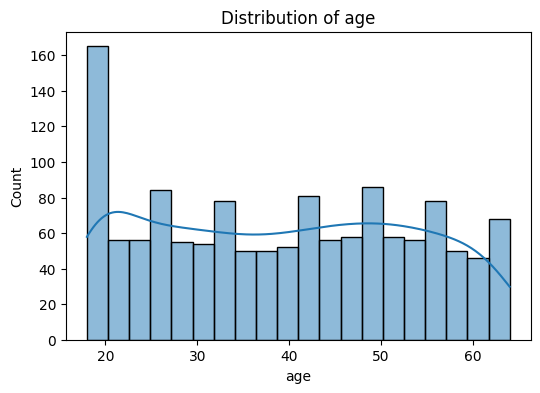

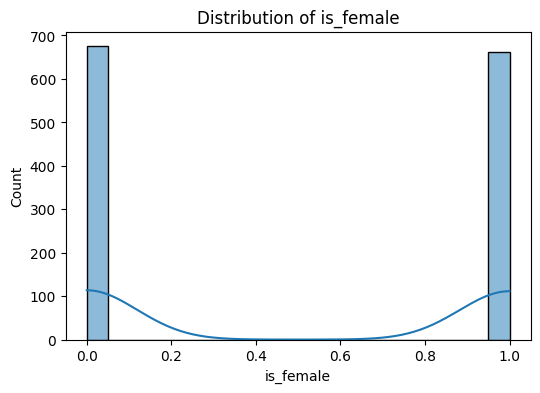

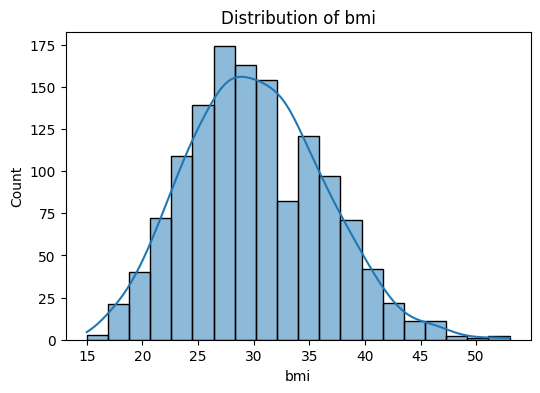

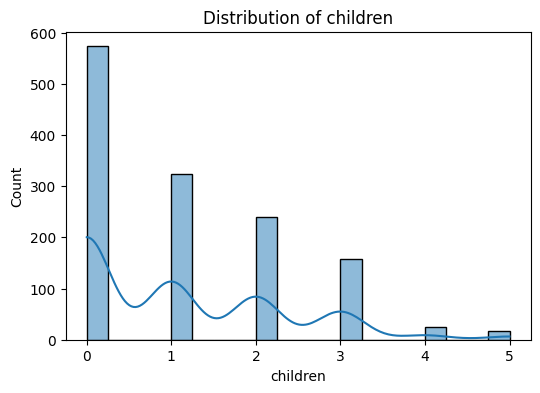

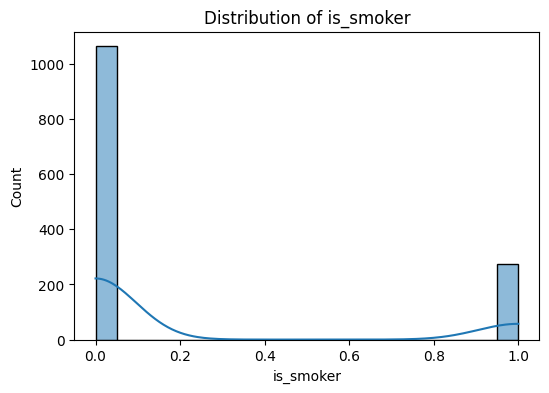

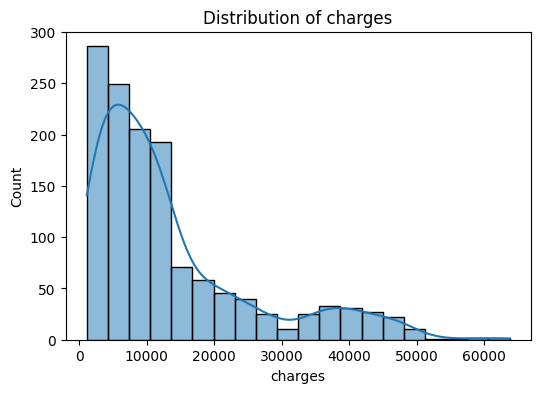

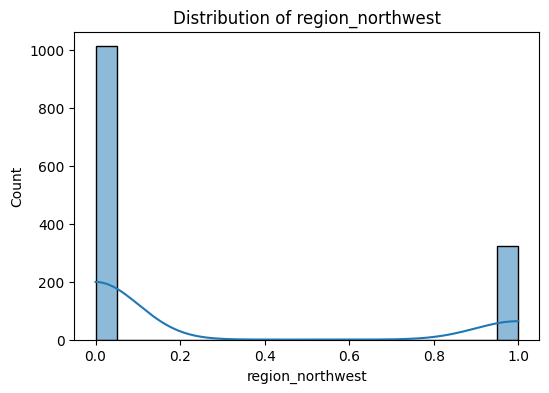

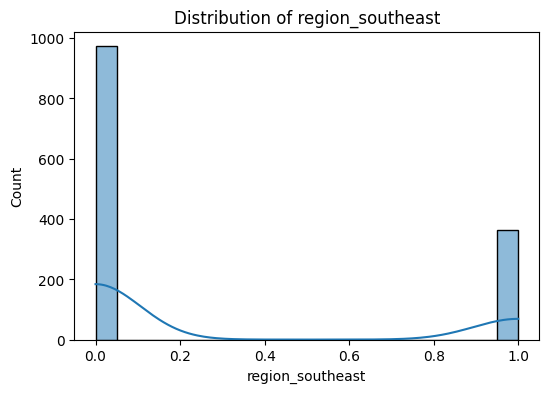

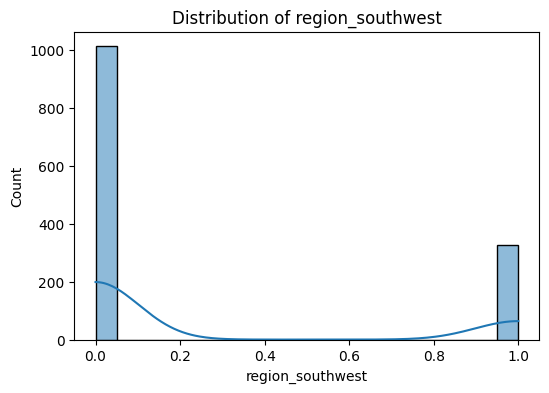

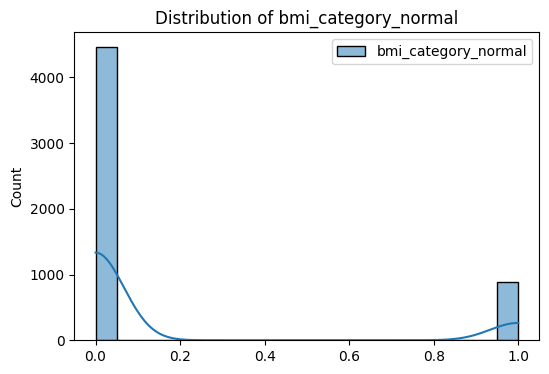

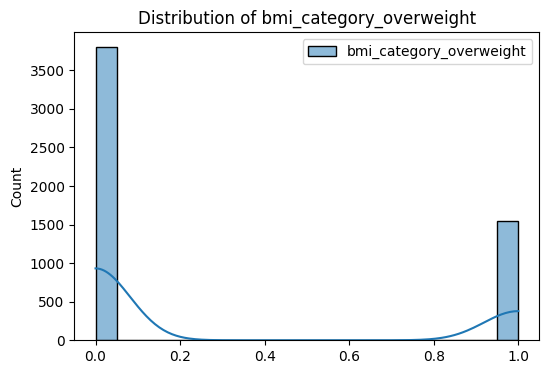

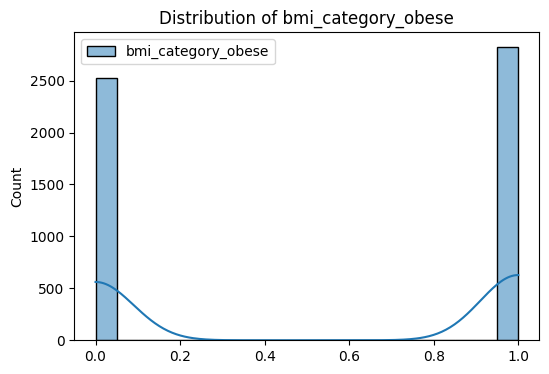

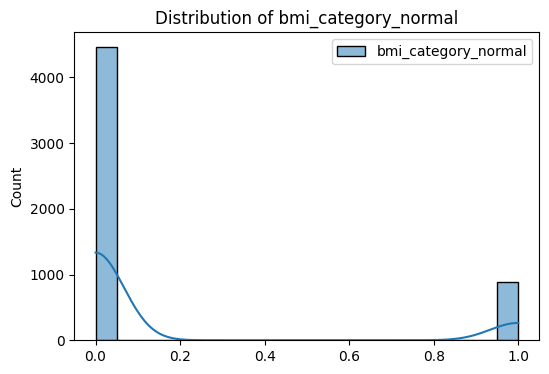

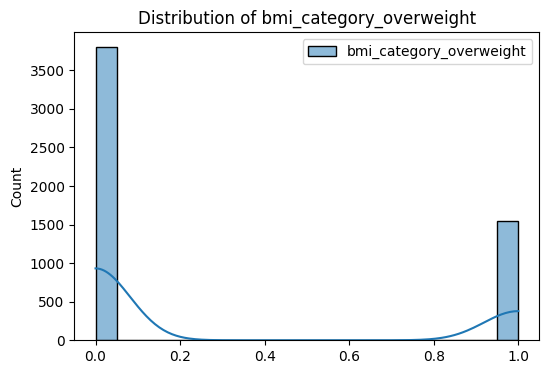

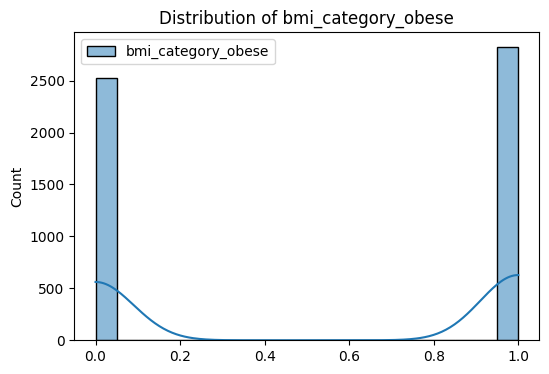

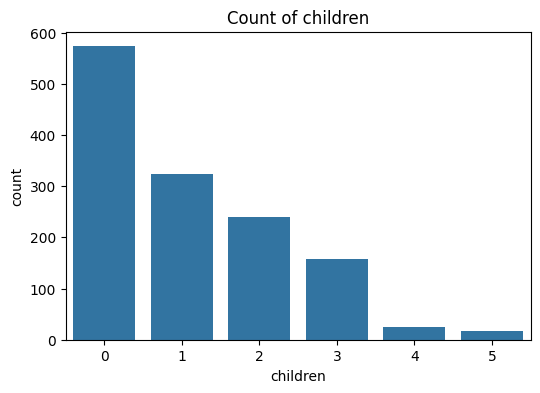

KeyError: 'sex'

<Figure size 600x400 with 0 Axes>

In [12]:
# ---- EDA PLOTS ----
numeric_columns = df.select_dtypes(include='number').columns

# Histograms for numeric columns
for col in numeric_columns:
    plt.figure(figsize=(6, 4))
    sns.histplot(df[col], kde=True, bins=20)
    plt.title(f'Distribution of {col}')
    plt.show()

# Countplots for categorical columns
for col in ['children', 'sex', 'smoker']:
    plt.figure(figsize=(6, 4))
    sns.countplot(x=df[col])
    plt.title(f'Count of {col}')
    plt.show()

# Boxplots for numeric columns
for col in numeric_columns:
    plt.figure(figsize=(6, 4))
    sns.boxplot(x=df[col])
    plt.title(f'Boxplot of {col}')
    plt.show()

# Heatmap
plt.figure(figsize=(6, 4))
df_cor = df.corr(numeric_only=True)
sns.heatmap(df_cor, annot=True, cmap='coolwarm')
plt.title('Correlation Matrix')
plt.show()

In [13]:
# ---- DATA CLEANING ----
print(f"Duplicates before: {df.duplicated().sum()}")
df = df.drop_duplicates()
print(f"Duplicates after: {df.duplicated().sum()}")

Duplicates before: 17
Duplicates after: 0


In [21]:
# ---- LABEL & ONE-HOT ENCODING ----
if 'sex' in df.columns:
    print("Sex Counts:")
    print(df['sex'].value_counts())
    df['sex'] = df['sex'].map({'male': 0, 'female': 1})
    df.rename(columns={'sex': 'is_female'}, inplace=True)
else:
    print("'sex' column is already processed or renamed.")

if 'smoker' in df.columns:
    print("\nSmoker Counts:")
    print(df['smoker'].value_counts())
    df['smoker'] = df['smoker'].map({'no': 0, 'yes': 1})
    df.rename(columns={'smoker': 'is_smoker'}, inplace=True)
else:
    print("'smoker' column is already processed or renamed.")

# One-Hot Encode Region if 'region' column is present
if 'region' in df.columns:
    df = pd.get_dummies(df, columns=['region'], drop_first=True)
    df = df.astype(int)
else:
    print("'region' column is already one-hot encoded.")

display(df.head())

'sex' column is already processed or renamed.
'smoker' column is already processed or renamed.
'region' column is already one-hot encoded.


,age,is_female,bmi,children,is_smoker,charges,region_northwest,region_southeast,region_southwest,bmi_category_normal,bmi_category_overweight,bmi_category_obese,charges_bin
0,-1.454322,1.013731,-0.516878,-0.914990,1.953847,16884,-0.566852,-0.610034,1.756897,-0.444772,1.569894,-1.057724,2
1,-1.525928,-0.986455,0.462938,-0.086604,-0.511811,1725,-0.566852,1.639253,-0.569185,-0.444772,-0.636986,0.945426,0
2,-0.809861,-0.986455,0.462938,1.570168,-0.511811,4449,-0.566852,1.639253,-0.569185,-0.444772,-0.636986,0.945426,0
3,-0.451828,-0.986455,-1.333391,-0.914990,-0.511811,21984,1.764129,-0.610034,-0.569185,2.248343,-0.636986,-1.057724,3
4,-0.523434,-0.986455,-0.353575,-0.914990,-0.511811,3866,1.764129,-0.610034,-0.569185,-0.444772,1.569894,-1.057724,0


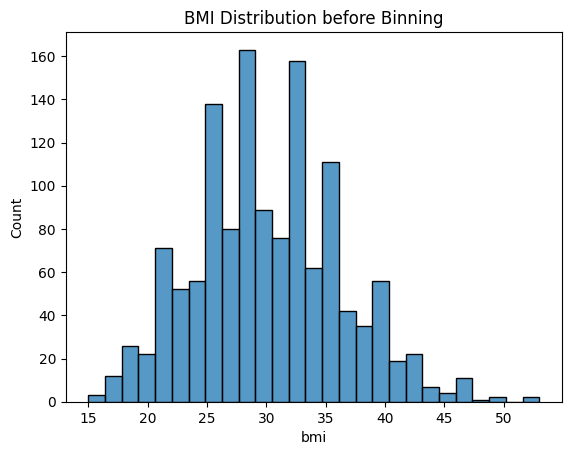

Columns after Feature Engineering:
['age', 'is_female', 'bmi', 'children', 'is_smoker', 'charges', 'region_northwest', 'region_southeast', 'region_southwest', 'bmi_category_normal', 'bmi_category_overweight', 'bmi_category_obese']


In [15]:
# ---- FEATURE ENGINEERING ----
sns.histplot(x=df['bmi'])
plt.title('BMI Distribution before Binning')
plt.show()

# Safely drop columns if they already exist to prevent duplication
df = df.loc[:, ~df.columns.duplicated()]
cols_to_drop = [c for c in df.columns if c.startswith('bmi_category')]
df = df.drop(columns=cols_to_drop, errors='ignore')

# Create BMI Category
df['bmi_category'] = pd.cut(df['bmi'],
                             bins=[0, 18.5, 24.9, 29.9, float('inf')],
                             labels=['underweight', 'normal', 'overweight', 'obese'])

df = pd.get_dummies(df, columns=['bmi_category'], drop_first=True)
df = df.astype(int)

print("Columns after Feature Engineering:")
print(df.columns.tolist())

In [16]:
# ---- PEARSON CORRELATION (unscaled data) ----
from scipy.stats import pearsonr

selected_features = ['age', 'is_female', 'bmi', 'children', 'is_smoker', 'charges',
                      'region_northwest', 'region_southeast', 'region_southwest',
                      'bmi_category_normal', 'bmi_category_overweight', 'bmi_category_obese']

correlations = {}
for feature in selected_features:
    if feature != 'charges':
        corr, p_value = pearsonr(df[feature], df['charges'])
        correlations[feature] = corr

sorted_corr = sorted(correlations.items(), key=lambda x: x[1], reverse=True)
print("Pearson correlation with charges:")
for feature, corr in sorted_corr:
    print(f"{feature:25} : {corr:.4f}")

Pearson correlation with charges:
is_smoker                 : 0.7872
age                       : 0.2924
bmi_category_obese        : 0.2029
bmi                       : 0.1986
region_southeast          : 0.0755
children                  : 0.0618
region_northwest          : -0.0390
region_southwest          : -0.0452
is_female                 : -0.0568
bmi_category_normal       : -0.1033
bmi_category_overweight   : -0.1235


In [22]:
# ---- CHI2 TEST (unscaled data) ----
from scipy.stats import chi2_contingency

cat_features = [
    'is_female', 'is_smoker',
    'region_northwest', 'region_southeast', 'region_southwest',
    'bmi_category_normal', 'bmi_category_overweight', 'bmi_category_obese'
]

alpha = 0.05
df['charges_bin'] = pd.qcut(df['charges'], q=4, labels=False)
chi2_results = {}

for col in cat_features:
    contingency = pd.crosstab(df[col], df['charges_bin'])
    chi2_stat, p_val, _, _ = chi2_contingency(contingency)
    decision = 'Reject Null (Keep Feature)' if p_val < alpha else 'Accept Null (Drop Feature)'
    chi2_results[col] = {
        'chi2_stat': chi2_stat,
        'p_value': p_val,
        'decision': decision
    }

results_df = pd.DataFrame(chi2_results).T
display(results_df)

,chi2_stat,p_value,decision
is_female,10.726237,0.013302,Reject Null (Keep Feature)
is_smoker,824.615428,0.0,Reject Null (Keep Feature)
region_northwest,1.164903,0.761434,Accept Null (Drop Feature)
region_southeast,16.51169,0.00089,Reject Null (Keep Feature)
region_southwest,5.160621,0.160406,Accept Null (Drop Feature)
bmi_category_normal,2.835212,0.417736,Accept Null (Drop Feature)
bmi_category_overweight,4.202494,0.240412,Accept Null (Drop Feature)
bmi_category_obese,8.423443,0.038025,Reject Null (Keep Feature)


In [23]:
# ---- FEATURE SCALING & EXPORT ----
from sklearn.preprocessing import StandardScaler

cols_to_scale = df.columns.drop('charges')
standard_scaler = StandardScaler()
scaled_array = standard_scaler.fit_transform(df[cols_to_scale])
df[cols_to_scale] = pd.DataFrame(scaled_array, columns=cols_to_scale, index=df.index)

df = df.drop(columns=['charges_bin'], errors='ignore')

print("Sample scaled BMI:")
print(df['bmi'].head())

# Save Data
df.to_csv("insurance_scaled.csv", index=False)
print("\nProcessed dataset saved as 'insurance_scaled.csv' successfully!")

Sample scaled BMI:
0   -0.516878
1    0.462938
2    0.462938
3   -1.333391
4   -0.353575
Name: bmi, dtype: float64

Processed dataset saved as 'insurance_scaled.csv' successfully!


In [27]:
from sklearn.model_selection import train_test_split

X = df.drop(columns=['charges'])
y = df['charges']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print(f"Training set shape: {X_train.shape}")
print(f"Testing set shape: {X_test.shape}")

Training set shape: (1056, 11)
Testing set shape: (264, 11)


In [28]:
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import r2_score, mean_absolute_error, root_mean_squared_error

# Initialize Models
models = {
    "Linear Regression": LinearRegression(),
    "Random Forest Regressor": RandomForestRegressor(random_state=42, n_estimators=100),
    "Gradient Boosting Regressor": GradientBoostingRegressor(random_state=42)
}

# Train and Evaluate Models
results = {}
for name, model in models.items():
    # Train
    model.fit(X_train, y_train)
    # Predict
    predictions = model.predict(X_test)

    # Evaluate metrics
    r2 = r2_score(y_test, predictions)
    mae = mean_absolute_error(y_test, predictions)
    rmse = root_mean_squared_error(y_test, predictions)

    results[name] = {
        "R2 Score": r2,
        "MAE": mae,
        "RMSE": rmse
    }

# Display Results
results_df = pd.DataFrame(results).T
display(results_df)

,R2 Score,MAE,RMSE
Linear Regression,0.786174,4150.096675,5785.643655
Random Forest Regressor,0.861085,2688.639103,4663.325096
Gradient Boosting Regressor,0.883070,2463.811799,4278.423588


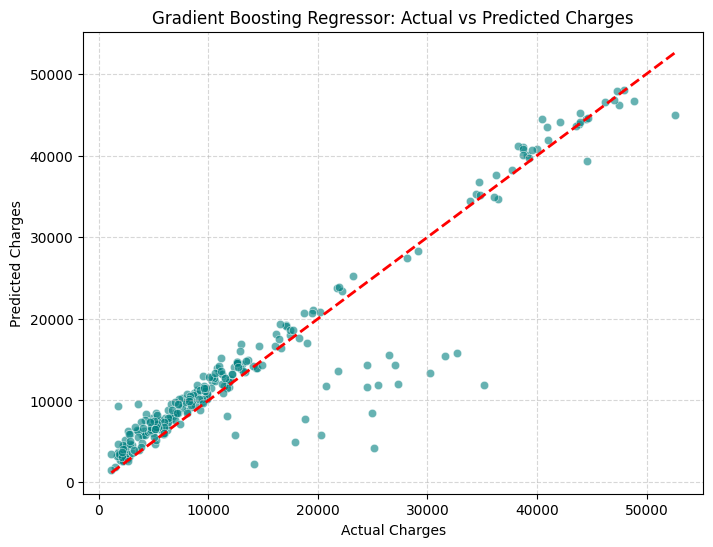

In [30]:
# ---- VISUALIZE MODEL PERFORMANCE ----
best_model = models["Gradient Boosting Regressor"]
y_pred = best_model.predict(X_test)

plt.figure(figsize=(8, 6))
sns.scatterplot(x=y_test, y=y_pred, alpha=0.6, color='teal')
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2)
plt.xlabel('Actual Charges')
plt.ylabel('Predicted Charges')
plt.title('Gradient Boosting Regressor: Actual vs Predicted Charges')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()